In [23]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import v2

In [24]:
from PIL import Image

def ddir(asset_name: str):
    return f"./data/assets/{asset_name}/"

def dpath(asset_name: str, number: int):
    return f"./data/assets/{asset_name}/{asset_name}_{number}.png"

img = Image.open(dpath("key", 1))

In [4]:
# load walls
from pathlib import Path
import shutil
'''
dir_path = "transformed_data"
if os.path.exists(dir_path):
    shutil.rmtree(dir_path)

os.makedirs(dir_path, exist_ok=True)
'''

'\ndir_path = "transformed_data"\nif os.path.exists(dir_path):\n    shutil.rmtree(dir_path)\n\nos.makedirs(dir_path, exist_ok=True)\n'

In [99]:
def overlay_save(asset_name: str):
    print("concatenating", asset_name)
    dir_path = f"transformed_data/{asset_name}"
    if os.path.exists(dir_path):
        shutil.rmtree(dir_path)
    os.makedirs(dir_path, exist_ok=True)

    floors = list(Path(ddir("floor")).iterdir())
    entity = list(Path(ddir(asset_name)).iterdir())
    count = 0
    for e in entity:
        foreground = Image.open(e).convert("RGBA")
        for f in floors:
            test_name = f"{asset_name}_{count}.png"
            background = Image.open(f).convert("RGBA")
            background.paste(foreground, (0, 0), mask=foreground)
            plt.imshow(background)
            background.save(f"{dir_path}/{test_name}")
            count += 1
'''
overlay_save("boots")
overlay_save("box")
overlay_save("coin")
overlay_save("exit")
overlay_save("floor")
overlay_save("gem")
overlay_save("ghost")
overlay_save("human")
overlay_save("key")
overlay_save("shield")
overlay_save("opened")
overlay_save("locked")
'''

'\noverlay_save("boots")\noverlay_save("box")\noverlay_save("coin")\noverlay_save("exit")\noverlay_save("floor")\noverlay_save("gem")\noverlay_save("ghost")\noverlay_save("human")\noverlay_save("key")\noverlay_save("shield")\noverlay_save("opened")\noverlay_save("locked")\n'

In [100]:

from PIL import Image, ImageEnhance
import numpy as np
def augmented_save(asset_name: str):
    print("concatenating", asset_name)
    dir_path = f"transformed_data/{asset_name}"
    if os.path.exists(dir_path):
        shutil.rmtree(dir_path)
    os.makedirs(dir_path, exist_ok=True)
    entity = list(Path(ddir(asset_name)).iterdir())
    count = 0
    for e in entity:
        img = Image.open(e).convert("RGBA")

        for angle in [90, 180, 270]:
            test_name = f"{asset_name}_{count}.png"
            img.rotate(angle, expand=True).save(f"{dir_path}/{count}.png")

        # Brightness
        for factor in np.linspace(0.6, 1.4, 50):
            test_name = f"{asset_name}_{count}.png"
            rgb, alpha = img.convert("RGB"), img.getchannel("A")
            bright = ImageEnhance.Brightness(rgb).enhance(factor)
            bright.putalpha(alpha)
            bright.save(f"{dir_path}/{count}.png")
            count += 1

"""
augmented_save("wall")
augmented_save("opened")
augmented_save("lava")
augmented_save("locked")
"""

'\naugmented_save("wall")\naugmented_save("opened")\naugmented_save("lava")\naugmented_save("locked")\n'

In [25]:
mappings = {}
mappings["boots"] = 0
mappings["box"] = 1
mappings["exit"] = 2
mappings["floor"] = 3
mappings["gem"] = 4
mappings["ghost"] = 5
mappings["human"] = 6
mappings["key"] = 7
mappings["lava"] = 8
mappings["locked"] = 9
mappings["opened"] = 10
mappings["shield"] = 11
mappings["coin"] = 12
mappings["wall"] = 13

In [ ]:
# Split the RAW sprites 80/20 first, then augment each split separately,
# so no sprite (or brightness/floor variant of it) appears in both train and test.
# locked/opened have transparent backgrounds, so they are pasted onto floors like the entities.
import random
import pandas as pd
from PIL import ImageEnhance

SEED = 2109
TRAIN_FRAC = 0.8
TILE_CLASSES = {"floor", "wall", "lava"}             # opaque full tiles
BRIGHTNESS = [0.7, 0.85, 1.0, 1.15, 1.3]
ROTATIONS = [0, 90, 180, 270]
MIN_IMAGES = 100                                     # classes below this get extra augmentation

def split_sprites(asset_name: str):
    files = sorted(Path(ddir(asset_name)).iterdir())
    random.Random(f"{SEED}-{asset_name}").shuffle(files)
    cutoff = int(TRAIN_FRAC * len(files))
    return {"train": files[:cutoff], "test": files[cutoff:]}

def augment_tile(path):
    img = Image.open(path).convert("RGB")
    for angle in ROTATIONS:
        rotated = img.rotate(angle)
        for factor in BRIGHTNESS:
            yield ImageEnhance.Brightness(rotated).enhance(factor)

SCALES = (0.4, 1.0)                                  # sprite size range relative to the tile

def augment_overlay(path, floors):
    # per floor: one full-size paste + one smaller sprite at a random spot (game sprites can be small)
    fg = Image.open(path).convert("RGBA")
    rng = random.Random(f"{SEED}-{path}")
    for f in floors:
        bg = Image.open(f).convert("RGBA")
        full = bg.copy()
        full.paste(fg, (0, 0), mask=fg)
        yield full.convert("RGB")

        size = int(fg.width * rng.uniform(*SCALES))
        small = fg.resize((size, size), Image.LANCZOS)
        x, y = rng.randint(0, bg.width - size), rng.randint(0, bg.height - size)
        bg.paste(small, (x, y), mask=small)
        yield bg.convert("RGB")

def extra_variants(img, rng):
    # random flip / rotate / brightness / contrast / small shift, per-split for classes with few images
    # ops = [Image.FLIP_LEFT_RIGHT, Image.FLIP_TOP_BOTTOM, Image.ROTATE_90, Image.ROTATE_180, Image.ROTATE_270]
    # out = img.transpose(rng.choice(ops))
    out = img
    out = ImageEnhance.Brightness(out).enhance(rng.uniform(0.7, 1.3))
    out = ImageEnhance.Contrast(out).enhance(rng.uniform(0.8, 1.2))
    dx, dy = rng.randint(-2, 2), rng.randint(-2, 2)
    return out.rotate(0, translate=(dx, dy), fillcolor=out.getpixel((0, 0)))

def build_split(out_root: str = "./transformed_data"):
    splits = {name: split_sprites(name) for name in mappings}
    for folder_name in ["train", "test"]:
        out_dir = Path(out_root) / folder_name
        if out_dir.exists():
            shutil.rmtree(out_dir)
        out_dir.mkdir(parents=True)

        floors = splits["floor"][folder_name]  # test overlays only use held-out floors
        indices, labels = [], []
        for asset_name, label in mappings.items():
            sprites = splits[asset_name][folder_name]
            n_before = len(indices)
            images = []
            for path in sprites:
                if asset_name in TILE_CLASSES:
                    images += augment_tile(path)
                else:
                    images += augment_overlay(path, floors)
            base = list(images)
            rng = random.Random(f"{SEED}-{asset_name}-{folder_name}")
            while base and len(images) < MIN_IMAGES:
                images.append(extra_variants(rng.choice(base), rng))
            for img in images:
                index = f"{len(indices):05d}"
                img.save(out_dir / f"{index}.png")
                indices.append(index)
                labels.append(label)
            print(f"{folder_name:5s} {asset_name:7s} sprites={len(sprites):2d} images={len(indices) - n_before}")
        pd.DataFrame({"index": indices, "label": labels}).to_csv(out_dir / "labels.csv", index=False)

    # sanity check: no raw sprite is in both splits
    for name, s in splits.items():
        assert not set(s["train"]) & set(s["test"]), name
    return splits

splits = build_split()

In [26]:
class GSDataset(Dataset):
    def __init__(self, train: bool = True, transform: torch.nn.Module = None):
        self.root_dir = f"./transformed_data"
        self.train = train
        self.transform = transform
        if self.train:
            self.data_dir = f"{self.root_dir}/train"
            self.labels_file = f"{self.root_dir}/train/labels.csv"
        else:
            self.data_dir = f"{self.root_dir}/test"
            self.labels_file = f"{self.root_dir}/test/labels.csv"
        with open(self.labels_file, 'r') as f:
            self.labels = [line.strip().split(',')[1] for line in f.readlines()[1:]]  # Skip header and get labels
        self.image_files = sorted([f"{self.data_dir}/{i:05d}.png" for i in range(len(self.labels))])

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> tuple:
        img_path = self.image_files[idx]
        image = Image.open(img_path).convert('RGB')  # Ensure image is in RGB format
        label = int(self.labels[idx])  # Convert label to integer
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

In [27]:

def get_augmentations(train: bool = False) -> transforms.Compose:
    if not train:
        return transforms.Compose([
            transforms.ToTensor(),
        ])

    # Random per-sample augmentation, applied fresh every epoch (train only)
    T = transforms.Compose([
          transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03),
          transforms.RandomGrayscale(p=0.2),
          transforms.RandomChoice([transforms.Resize(s, antialias=True) for s in (32, 64, 96, 112, 128)]),
          transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.BILINEAR),
          transforms.ToTensor(),
    ])

    return T

T = get_augmentations()                  # eval / inference: no randomness
T_train = get_augmentations(train=True)

def get_test_transform(size: int) -> transforms.Compose:
    # simulate a game cell of `size` px being upscaled to 128 at inference
    return transforms.Compose([
        transforms.Resize(size, antialias=True),
        transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.ToTensor(),
    ])

In [28]:
df_train = GSDataset(train=True, transform=T_train)
df_test = GSDataset(train=False, transform=T)
df_train_loader = DataLoader(df_train, batch_size=32, shuffle=True, drop_last=True)

<class 'torch.Tensor'> torch.Size([32, 3, 128, 128])
<class 'torch.Tensor'> torch.Size([32])


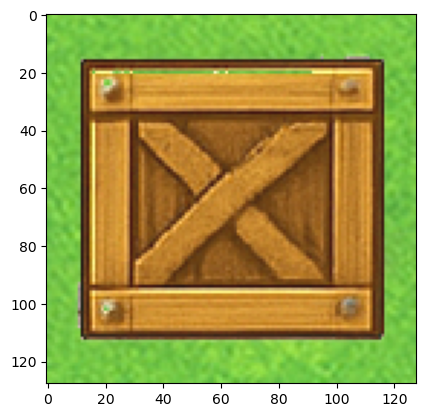

In [41]:
for batch_idx, (images, labels) in enumerate(df_train_loader):
    # 'images' and 'labels' are automatically PyTorch Tensors!
    
    print(type(images), images.shape)  # e.g., torch.Tensor, torch.Size([32, 3, 128, 128])
    print(type(labels), labels.shape)  # e.g., torch.Tensor, torch.Size([32])

    plt.imshow(images[0].permute(1, 2, 0)) 
    # Break after the first batch just to inspect
    break

In [42]:
class GSCNN(nn.Module):
    def __init__(self, classes: int):
        super().__init__()
        self.conv = nn.Sequential(
                       nn.Conv2d(3, 16, (4, 4), padding=1),
                       nn.BatchNorm2d(16),
                       nn.MaxPool2d((2,2)),
                       nn.LeakyReLU(0.01),

                       nn.Conv2d(16, 32, (3, 3), padding=1),
                       nn.BatchNorm2d(32),
                       nn.MaxPool2d((2, 2)),
                       nn.LeakyReLU(0.01),

                       nn.Conv2d(32, 64, (3, 3), padding=1),
                       nn.BatchNorm2d(64),
                       nn.MaxPool2d((2,2)),
                       nn.LeakyReLU(0.01),

                       nn.Conv2d(64, 128, (3, 3), padding=1),
                       nn.BatchNorm2d(128),
                       nn.MaxPool2d((2,2)),
                       nn.LeakyReLU(0.01),
                    )

        self.fc = nn.Sequential(
                       nn.Linear(128, classes)
                    )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv(x)
        x = x.view(x.shape[0], 128, -1).mean(2) # GAP – do not remove this line
        out = self.fc(x)
        return out
    
    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        out = self.forward(x)
        return torch.softmax(out, dim = 1)

In [15]:
def train_model(model: nn.Module, dataloader: DataLoader, epochs: int = 20, device: torch.device = torch.device("cpu")):
    losses = []
    model = model.to(device) 

    parameters = [layer for _, layer in model.named_parameters()]
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    model.train() 
    for i in range(epochs):
        epoch_loss = 0.0
        samples_seen = 0
        for x_batch, y_batch in dataloader:
            x_batch = x_batch.to(device) 
            y_batch = y_batch.to(device) 
            y_pred = model.forward(x_batch)
            loss = nn.CrossEntropyLoss()(y_pred, y_batch)

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            epoch_loss += loss.item() * x_batch.shape[0]
            samples_seen += x_batch.shape[0]
        epoch_loss /= len(dataloader.dataset)
        print(f"Epoch {i+1}/{epochs}, Loss: {epoch_loss:.4f}")
        losses.append(epoch_loss)

    return model, losses

In [16]:
gscnn = GSCNN(14)

In [ ]:
model, losses1 = train_model(gscnn, df_train_loader, epochs = 10, device='cpu')

Epoch 1/10, Loss: 0.0130
Epoch 2/10, Loss: 0.0123
Epoch 3/10, Loss: 0.0097
Epoch 4/10, Loss: 0.0047
Epoch 5/10, Loss: 0.0029
Epoch 6/10, Loss: 0.0034


In [18]:
def get_accuracy(scores: torch.Tensor, labels: torch.Tensor) -> int | float:
    predicted = torch.argmax(scores, axis=1)
    assert predicted.shape == labels.shape
    return torch.sum((predicted == labels)) / predicted.shape[0]

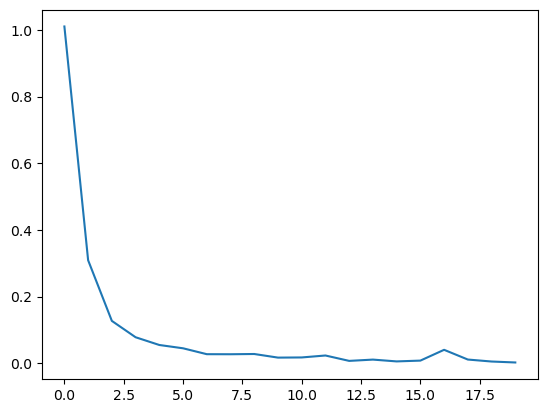

In [19]:
plt.plot(losses1)

In [20]:
device = 'cpu'
inv_mappings = {v: k for k, v in mappings.items()}

def evaluate(model, dataset):
    loader = DataLoader(dataset, batch_size=256)
    correct, total = torch.zeros(14), torch.zeros(14)
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            pred = model(x.to(device)).argmax(dim=1).cpu()
            for c in range(14):
                mask = y == c
                correct[c] += (pred[mask] == c).sum()
                total[c] += mask.sum()
    return correct, total

for size in (128, 96, 64, 48, 32):
    df_test.transform = get_test_transform(size)
    correct, total = evaluate(model, df_test)
    worst = sorted(range(14), key=lambda c: correct[c] / total[c])[:3]
    print(f"size {size:3d}: acc {correct.sum() / total.sum():.4f} | worst: " +
          ", ".join(f"{inv_mappings[c]} {int(correct[c])}/{int(total[c])}" for c in worst))
df_test.transform = T

size 128: acc 0.9971 | worst: locked 96/100, boots 100/100, box 100/100
size  96: acc 0.9971 | worst: locked 96/100, boots 100/100, box 100/100
size  64: acc 0.9986 | worst: locked 98/100, boots 100/100, box 100/100
size  48: acc 1.0000 | worst: boots 100/100, box 100/100, exit 100/100
size  32: acc 0.9986 | worst: gem 98/100, boots 100/100, box 100/100


In [21]:
# Dump model
# Auto-generate a loader snippet for the trained PyTorch model
from utils import generate_torch_loader_snippet

snippet = generate_torch_loader_snippet(model, prefer="auto", compression="zlib")
print(snippet)

# You would copy the FULL printed function definition (def get_model(...): ...) into your agent source code.
# Then inside Agent.__init__ you could do: self.model = get_model()

def get_model(device: str = "cpu", dtype: str | None = None):
    """
    Return a TorchScript model loaded from an embedded, base64-encoded compressed blob.
    Self-contained: no need for the original Python class.

    Args:
        device: Where to map the model (e.g., "cpu", "cuda", "cuda:0").
        dtype: Optional dtype to convert parameters/buffers to (e.g., "float32", "float16").
    """
    import base64, io, torch
    import zlib as _z; _decomp = _z.decompress
    _blob_b64 = "..."
    _raw = _decomp(base64.b64decode(_blob_b64))
    buf = io.BytesIO(_raw)
    m = torch.jit.load(buf, map_location=device)
    if dtype is not None:
        dt = getattr(torch, dtype) if isinstance(dtype, str) else dtype
        for p in m.parameters():
            p.data = p.data.to(dt)
        for b in m.buffers():
            b.data = b.data.to(dt)
    m.eval()
    return m



In [116]:
def get_model(device: str = "cpu", dtype: str | None = None):
    """
    Return a TorchScript model loaded from an embedded, base64-encoded compressed blob.
    Self-contained: no need for the original Python class.

    Args:
        device: Where to map the model (e.g., "cpu", "cuda", "cuda:0").
        dtype: Optional dtype to convert parameters/buffers to (e.g., "float32", "float16").
    """
    import base64, io, torch
    import zlib as _z; _decomp = _z.decompress
    _blob_b64 = "..."
    _raw = _decomp(base64.b64decode(_blob_b64))
    buf = io.BytesIO(_raw)
    m = torch.jit.load(buf, map_location=device)
    if dtype is not None:
        dt = getattr(torch, dtype) if isinstance(dtype, str) else dtype
        for p in m.parameters():
            p.data = p.data.to(dt)
        for b in m.buffers():
            b.data = b.data.to(dt)
    m.eval()
    return m

extracted_model = get_model()
img = Image.open(list(Path(ddir("wall")).iterdir())[2])
x_new = T(img.convert('RGB')).unsqueeze(0)
with torch.no_grad():
    probs = torch.softmax(extracted_model(x_new), dim = 1)
    pred_class = probs.argmax(dim=1).item()
    print(pred_class, inv_mappings[pred_class])
plt.figure(figsize=(2,2))
plt.imshow(img)

NameError: name 'dfdir' is not defined